# Week 1 — Data Collection, Quality Checks & Exploratory Analysis

**Dataset:** Online Retail (UCI Machine Learning Repository), UK-based online gift retailer,
transactions from 2010-12-01 to 2011-12-09. Raw file kept unchanged in `data/raw/`.

**Outputs of this notebook**

| Output | Location |
|---|---|
| Data dictionary | `reports/data_dictionary.csv` |
| Data-quality report | `reports/data_quality_report.csv` |
| Cleaning log (rows removed per rule) | `reports/cleaning_log.csv` |
| Cleaned transactions | `data/interim/cleaned_sales.csv` |
| Weekly product demand panel (input for Week 2) | `data/processed/weekly_product_demand.csv` |
| Product demand profile / intermittency | `reports/demand_profile.csv` |
| Figures | `reports/figures/` |

All cleaning logic lives in `src/data_cleaning.py` so later weeks reuse exactly the same rules.


## 1. Setup

In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent          # notebook runs from notebooks/
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.data_cleaning import (
    load_raw, clean_sales, save_clean_sales, load_clean_sales,
    trading_calendar, build_weekly_panel, demand_profile,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RAW_FILE      = PROJECT_DIR / "data" / "raw" / "Online Retail.xlsx"
INTERIM_DIR   = PROJECT_DIR / "data" / "interim"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR    = PROJECT_DIR / "reports"
FIG_DIR       = REPORT_DIR / "figures"
for d in (INTERIM_DIR, PROCESSED_DIR, REPORT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

print("Raw file exists:", RAW_FILE.exists())

Raw file exists: True


## 2. Load raw data

In [5]:
df = load_raw(RAW_FILE)      # StockCode / InvoiceNo read as text
print("Dataset loaded:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)

Dataset loaded: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  string        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(3), string(1)
memory usage: 33.1 MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,3958,85123A,2380,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4211,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data dictionary (source and meaning of each field)

In [6]:
field_meaning = {
    "InvoiceNo":   "Invoice number (6 digits). Starts with 'C' = cancellation.",
    "StockCode":   "Product code. Real products start with 5 digits (e.g. 85123A); others are postage, fees or adjustments.",
    "Description": "Product name. Can vary slightly for the same StockCode, so StockCode is the product key.",
    "Quantity":    "Units per invoice line. Negative = cancellation, return or stock adjustment.",
    "InvoiceDate": "Date and time the invoice was created.",
    "UnitPrice":   "Price per unit in GBP (£). Zero or negative = free items / bad-debt adjustments.",
    "CustomerID":  "5-digit customer identifier. Missing for ~25% of lines (guest/unregistered).",
    "Country":     "Country where the customer resides.",
}

data_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Unique Values": df.nunique().values,
    "Meaning": [field_meaning[c] for c in df.columns],
    "Source": "UCI Online Retail dataset (data/raw/Online Retail.xlsx)",
})
data_dictionary.to_csv(REPORT_DIR / "data_dictionary.csv", index=False)
display(data_dictionary)

,Column,Data Type,Missing Values,Unique Values,Meaning,Source
0,InvoiceNo,str,0,25900,Invoice number (6 digits). Starts with 'C' = c...,UCI Online Retail dataset (data/raw/Online Ret...
1,StockCode,str,0,3958,Product code. Real products start with 5 digit...,UCI Online Retail dataset (data/raw/Online Ret...
2,Description,string,1454,4211,Product name. Can vary slightly for the same S...,UCI Online Retail dataset (data/raw/Online Ret...
3,Quantity,int64,0,722,Units per invoice line. Negative = cancellatio...,UCI Online Retail dataset (data/raw/Online Ret...
4,InvoiceDate,datetime64[us],0,23260,Date and time the invoice was created.,UCI Online Retail dataset (data/raw/Online Ret...
5,UnitPrice,float64,0,1630,Price per unit in GBP (£). Zero or negative = ...,UCI Online Retail dataset (data/raw/Online Ret...
6,CustomerID,float64,135080,4372,5-digit customer identifier. Missing for ~25% ...,UCI Online Retail dataset (data/raw/Online Ret...
7,Country,str,0,38,Country where the customer resides.,UCI Online Retail dataset (data/raw/Online Ret...


## 4. Data-quality report (raw data)

In [7]:
is_product = df["StockCode"].str.match(r"^\d{5}")

quality_report = pd.DataFrame({
    "Metric": [
        "Total Rows", "Total Columns", "Duplicate Rows",
        "Missing Product Descriptions", "Missing Customer IDs",
        "Negative Quantities", "Zero Quantities", "Non-Positive Unit Prices",
        "Cancellation Invoices (lines)", "Non-Product Stock Codes (lines)",
    ],
    "Value": [
        len(df), df.shape[1], df.duplicated().sum(),
        df["Description"].isna().sum(), df["CustomerID"].isna().sum(),
        (df["Quantity"] < 0).sum(), (df["Quantity"] == 0).sum(), (df["UnitPrice"] <= 0).sum(),
        df["InvoiceNo"].str.startswith("C").sum(), (~is_product).sum(),
    ],
})
quality_report["Percentage (%)"] = (quality_report["Value"] / len(df) * 100).round(2)
quality_report.loc[quality_report["Metric"].isin(["Total Rows", "Total Columns"]), "Percentage (%)"] = np.nan

quality_report.to_csv(REPORT_DIR / "data_quality_report.csv", index=False)
display(quality_report)

print("Non-product codes found:")
display(df.loc[~is_product, "StockCode"].value_counts().head(15).to_frame("lines"))

,Metric,Value,Percentage (%)
0,Total Rows,541909,NaN
1,Total Columns,8,NaN
2,Duplicate Rows,5268,0.97
3,Missing Product Descriptions,1454,0.27
4,Missing Customer IDs,135080,24.93
5,Negative Quantities,10624,1.96
6,Zero Quantities,0,0.00
7,Non-Positive Unit Prices,2517,0.46
8,Cancellation Invoices (lines),9288,1.71
9,Non-Product Stock Codes (lines),2995,0.55


Non-product codes found:


,lines
StockCode,
POST,1256
DOT,710
M,572
C2,144
D,77
S,63
BANK CHARGES,37
AMAZONFEE,34
CRUK,16


### Cancelled bulk orders
Some very large orders were cancelled almost immediately. Removing only the negative
cancellation line would leave the original order inside the demand data as a huge fake spike.

In [8]:
display(df[df["Quantity"].abs() > 50000][["InvoiceNo", "StockCode", "Description",
                                          "Quantity", "InvoiceDate", "CustomerID"]])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,12346.0
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,12346.0
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,16446.0
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,16446.0


## 5. Clean the data (rules in `src/data_cleaning.py`)

In [9]:
# Scope decision: keep all countries for now (UK ≈ 91% of lines).
# To restrict, pass countries=["United Kingdom"].
sales, cleaning_log = clean_sales(df, countries=None, return_log=True)

cleaning_log.to_csv(REPORT_DIR / "cleaning_log.csv", index=False)
display(cleaning_log)

print("Original rows:", len(df))
print("Rows retained:", len(sales))
print("Largest remaining order lines:")
display(sales.nlargest(5, "Quantity")[["InvoiceNo", "Description", "Quantity", "InvoiceDate"]])

,Step,Rows before,Rows removed,Rows after,Rule
0,Invalid dates,541909,0,541909,InvoiceDate could not be parsed
1,Exact duplicates,541909,5268,536641,All 8 columns identical
2,Non-product codes,536641,2989,533652,"POST, DOT, M, D, C2, S, BANK CHARGES, AMAZONFE..."
3,Fully cancelled orders,533652,5610,528042,Order + matching cancellation removed (same cu...
4,Non-positive qty / price,528042,8343,519699,"Remaining cancellations, returns, adjustments ..."


Original rows: 541909
Rows retained: 519699
Largest remaining order lines:


,InvoiceNo,Description,Quantity,InvoiceDate
403762,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00
197207,554868,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00
93267,544612,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00
259218,560599,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,2011-07-19 17:04:00
153477,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00


In [10]:
save_clean_sales(sales, INTERIM_DIR / "cleaned_sales.csv")

# Check the file reloads with the right types (StockCode must stay text, dates must parse)
check = load_clean_sales(INTERIM_DIR / "cleaned_sales.csv")
print(check.dtypes)
assert check["StockCode"].map(type).eq(str).all()
assert len(check) == len(sales)

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
Revenue               float64
dtype: object


## 6. Trading calendar — true zeros vs closed days

In [11]:
calendar = trading_calendar(sales)
closed = calendar[~calendar["is_trading_day"]]

print("Days in date range:", len(calendar))
print("Days with no transactions:", len(closed))
display(closed["weekday"].value_counts().to_frame("closed days"))
print("Closed days that are not Saturdays (holidays):")
print(closed.loc[closed["weekday"] != "Saturday", "date"].dt.date.tolist())

Days in date range: 374
Days with no transactions: 69


,closed days
weekday,
Saturday,53
Monday,6
Friday,4
Sunday,3
Tuesday,1
Wednesday,1
Thursday,1


Closed days that are not Saturdays (holidays):
[datetime.date(2010, 12, 24), datetime.date(2010, 12, 26), datetime.date(2010, 12, 27), datetime.date(2010, 12, 28), datetime.date(2010, 12, 29), datetime.date(2010, 12, 30), datetime.date(2010, 12, 31), datetime.date(2011, 1, 2), datetime.date(2011, 1, 3), datetime.date(2011, 4, 22), datetime.date(2011, 4, 24), datetime.date(2011, 4, 25), datetime.date(2011, 4, 29), datetime.date(2011, 5, 2), datetime.date(2011, 5, 30), datetime.date(2011, 8, 29)]


The shop never trades on Saturdays and closes over Christmas and UK bank holidays.
These days are **missing (shop closed)**, not zero demand, and are excluded from daily plots.

## 7. Exploratory analysis

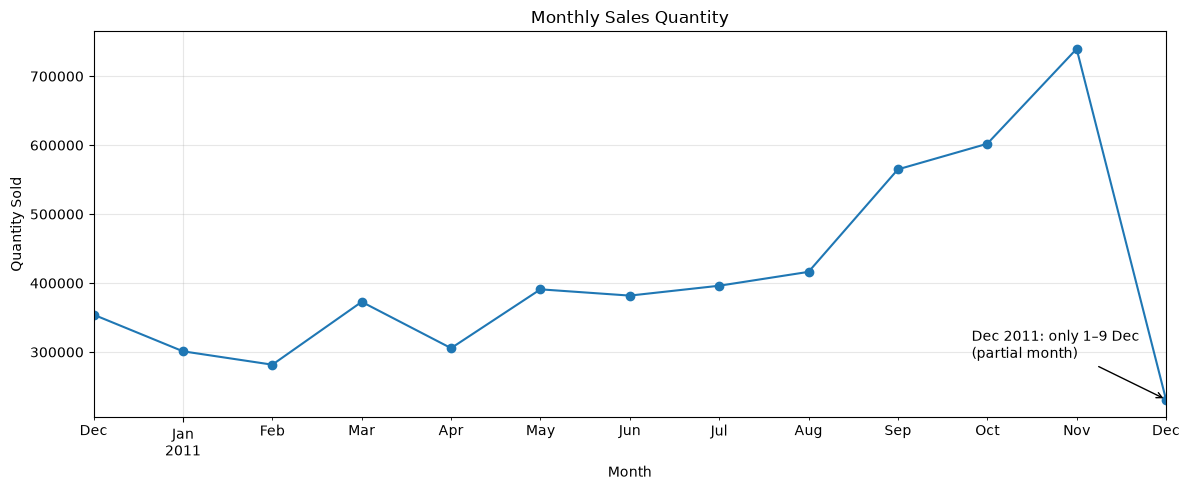

In [12]:
monthly_demand = sales.set_index("InvoiceDate")["Quantity"].resample("MS").sum()

ax = monthly_demand.plot(figsize=(12, 5), marker="o", title="Monthly Sales Quantity")
ax.annotate("Dec 2011: only 1–9 Dec\n(partial month)",
            xy=(monthly_demand.index[-1], monthly_demand.iloc[-1]),
            xytext=(-140, 30), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"))
plt.xlabel("Month"); plt.ylabel("Quantity Sold"); plt.grid(True, alpha=0.3)
save_fig("01_monthly_quantity")

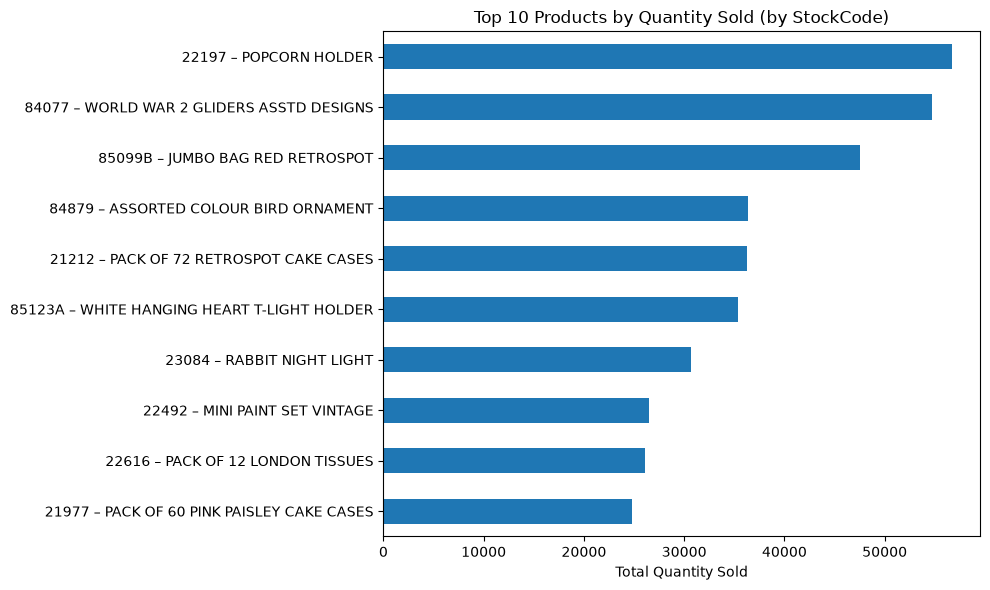

In [13]:
top_products = (
    sales.groupby("StockCode")
    .agg(Quantity=("Quantity", "sum"),
         Description=("Description", lambda x: x.mode().iat[0]))
    .nlargest(10, "Quantity")
)
top_products["Label"] = top_products.index + " – " + top_products["Description"]

top_products.set_index("Label")["Quantity"].sort_values().plot(
    kind="barh", figsize=(10, 6), title="Top 10 Products by Quantity Sold (by StockCode)")
plt.xlabel("Total Quantity Sold"); plt.ylabel("")
save_fig("02_top10_products")

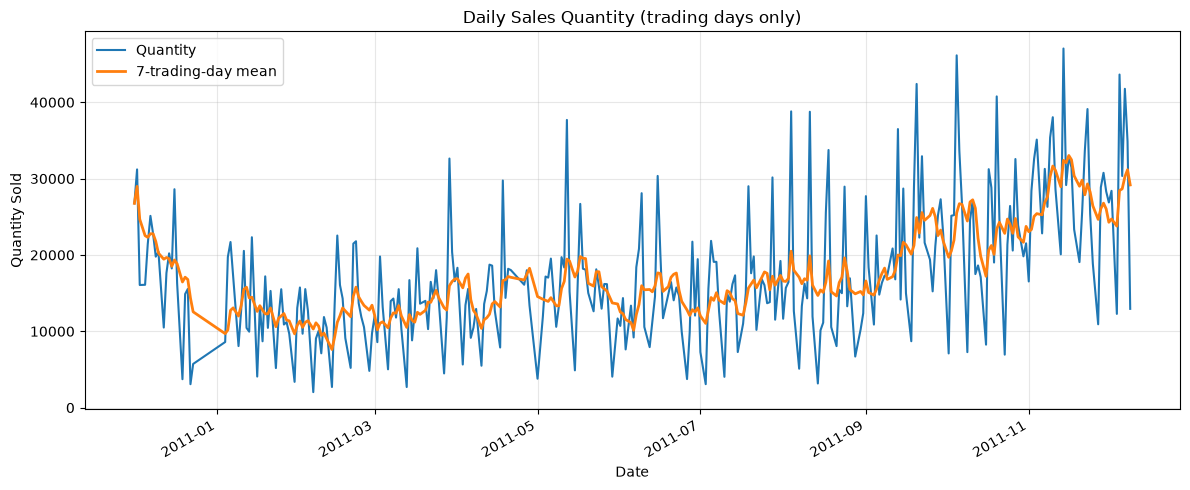

In [14]:
daily_demand = sales.set_index("InvoiceDate")["Quantity"].resample("D").sum()
trading_days = calendar.loc[calendar["is_trading_day"], "date"]
daily_demand = daily_demand.reindex(trading_days)          # closed days dropped, not zero

daily_demand.plot(figsize=(12, 5), title="Daily Sales Quantity (trading days only)")
daily_demand.rolling(7, min_periods=1).mean().plot(label="7-trading-day mean", linewidth=2)
plt.xlabel("Date"); plt.ylabel("Quantity Sold"); plt.legend(); plt.grid(True, alpha=0.3)
save_fig("03_daily_quantity")

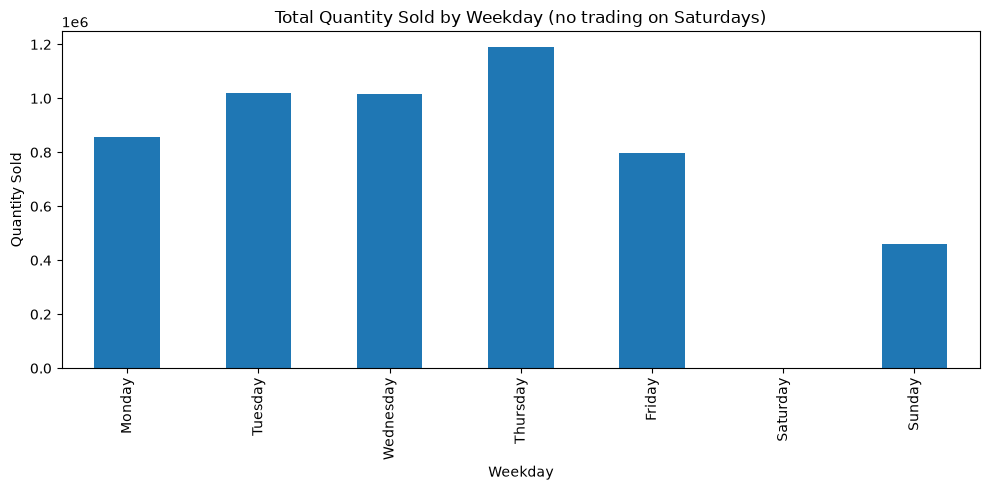

In [15]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_demand = (sales.assign(Weekday=sales["InvoiceDate"].dt.day_name())
                       .groupby("Weekday")["Quantity"].sum()
                       .reindex(order, fill_value=0))

weekday_demand.plot(kind="bar", figsize=(10, 5),
                    title="Total Quantity Sold by Weekday (no trading on Saturdays)")
plt.ylabel("Quantity Sold")
save_fig("04_weekday_quantity")

In [16]:
country_share = (sales.groupby("Country")["Quantity"].sum()
                      .sort_values(ascending=False) / sales["Quantity"].sum() * 100).round(2)
display(country_share.head(10).to_frame("% of units"))

,% of units
Country,
United Kingdom,82.91
Netherlands,3.75
EIRE,2.68
Germany,2.20
France,2.06
Australia,1.56
Sweden,0.67
Switzerland,0.57
Spain,0.50


## 8. Weekly product demand panel (input for Week 2)

In [18]:
weekly = build_weekly_panel(sales)
weekly.to_csv(PROCESSED_DIR / "weekly_product_demand.csv", index=False)

print("Panel shape:", weekly.shape)
print("Products:", weekly["StockCode"].nunique(), "| Weeks:", weekly["week_start"].nunique())
display(weekly.drop_duplicates("week_start")
              .query("store_closed or is_partial_week")
              [["week_start", "trading_days", "store_closed", "is_partial_week"]])
display(weekly.head())

Panel shape: (176363, 10)
Products: 3786 | Weeks: 54


,week_start,trading_days,store_closed,is_partial_week
0,2010-11-29,4,False,True
4,2010-12-27,0,True,False
53,2011-12-05,5,False,True


,StockCode,Description,week_start,units_sold,revenue,n_orders,avg_unit_price,trading_days,store_closed,is_partial_week
0,10002,INFLATABLE POLITICAL GLOBE,2010-11-29,70,65.17,7,1.081429,4,False,True
1,10002,INFLATABLE POLITICAL GLOBE,2010-12-06,138,127.02,14,1.197143,6,False,False
2,10002,INFLATABLE POLITICAL GLOBE,2010-12-13,41,38.90,8,1.255000,6,False,False
3,10002,INFLATABLE POLITICAL GLOBE,2010-12-20,2,3.32,1,1.660000,4,False,False
4,10002,INFLATABLE POLITICAL GLOBE,2010-12-27,0,0.00,0,NaN,0,True,False


**Panel rules**
- Weeks start on Monday. Each product starts at its first sale week (no zeros before launch).
- `units_sold = 0` in an open week = true zero demand.
- `store_closed = True` (week of 27 Dec 2010) and `is_partial_week = True` (first and last week)
  should be excluded or handled explicitly when building features and evaluating models.

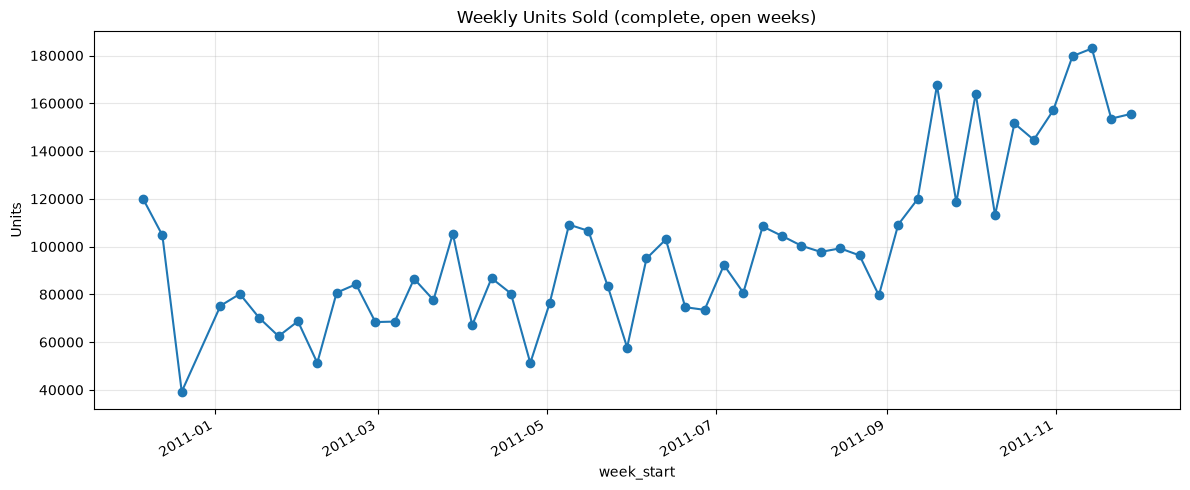

In [19]:
weekly_total = (weekly[~weekly["store_closed"] & ~weekly["is_partial_week"]]
                .groupby("week_start")["units_sold"].sum())
weekly_total.plot(figsize=(12, 5), marker="o", title="Weekly Units Sold (complete, open weeks)")
plt.ylabel("Units"); plt.grid(True, alpha=0.3)
save_fig("05_weekly_total")

## 9. Demand profile — intermittent demand

In [20]:
profile = demand_profile(weekly)
profile.to_csv(REPORT_DIR / "demand_profile.csv", index=False)

display(profile["demand_class"].value_counts().to_frame("products"))
display(profile.head(10))

for t in (0.5, 0.8, 0.9):
    print(f"Products selling in ≥{int(t*100)}% of weeks:",
          (profile["pct_weeks_with_sales"] >= t).sum())

,products
demand_class,
lumpy,1494
erratic,1226
intermittent,589
smooth,316
insufficient data,160


,StockCode,total_units,weeks_observed,weeks_with_sales,pct_weeks_with_sales,ADI,CV2,demand_class
0,22197,51727.0,51.0,51.0,1.000000,1.00,0.955028,erratic
1,84077,50229.0,51.0,50.0,0.980392,1.02,0.840686,erratic
2,85099B,46347.0,51.0,51.0,1.000000,1.00,0.266742,smooth
3,21212,34987.0,51.0,51.0,1.000000,1.00,0.321775,smooth
4,84879,34757.0,51.0,51.0,1.000000,1.00,0.655893,erratic
5,85123A,33715.0,51.0,51.0,1.000000,1.00,0.395582,smooth
6,23084,27506.0,30.0,30.0,1.000000,1.00,2.653143,erratic
7,22492,25799.0,51.0,51.0,1.000000,1.00,0.660921,erratic
8,22616,24813.0,51.0,51.0,1.000000,1.00,0.960758,erratic
9,21977,24133.0,51.0,51.0,1.000000,1.00,0.927908,erratic


Products selling in ≥50% of weeks: 2205
Products selling in ≥80% of weeks: 1443
Products selling in ≥90% of weeks: 1155


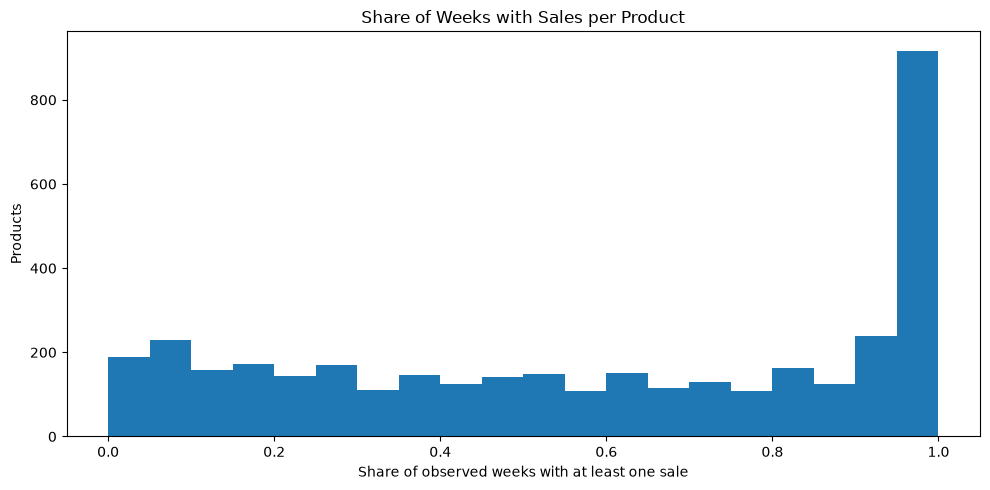

In [21]:
profile["pct_weeks_with_sales"].plot(kind="hist", bins=20, figsize=(10, 5),
    title="Share of Weeks with Sales per Product")
plt.xlabel("Share of observed weeks with at least one sale"); plt.ylabel("Products")
save_fig("06_sales_frequency_hist")

## 10. Summary of findings and limitations

**Key findings**
- **Data volume:** 541,909 raw invoice lines → **519,699** clean product sales lines (see `reports/cleaning_log.csv`).
- **Duplicates:** 5,268 exact duplicates removed. 2,989 non-product lines (postage, fees, manual adjustments, gift vouchers) removed.
- **Cancelled orders:** 5,610 lines (orders plus their exact cancellations) removed. This includes the 80,995-unit and 74,215-unit
  orders that were cancelled immediately and would otherwise appear as fake demand spikes.
- **Trading calendar:** the shop never trades on Saturdays and closes over Christmas (24 Dec 2010 – 3 Jan 2011) and UK bank holidays.
  Those days are treated as closed, not zero demand.
- **Trend and seasonality:** demand is fairly flat from January to August 2011, then rises strongly from September to November
  (pre-Christmas season). With only ~12 months of data, yearly seasonality cannot be estimated from repeated cycles.
- **Geography:** the United Kingdom accounts for ~83% of units (~91% of lines).
- **Intermittent demand:** of 3,786 products, only 316 are *smooth*; most are *erratic* or *lumpy*.
  1,443 products sell in at least 80% of weeks, which makes them sensible candidates for product-level forecasting.

**Decisions carried into Week 2**
- Forecast at **weekly product (StockCode) level** using `data/processed/weekly_product_demand.csv`.
- Exclude or flag `store_closed` and `is_partial_week` weeks in features and evaluation.
- Pick a forecastable subset (e.g. top products by volume with ≥80% weeks with sales); handle the rest with simple methods or aggregate them.

**Limitations**
- **No inventory, stockout, promotion or supplier lead-time fields.** Observed sales may understate true demand during stockouts,
  and this cannot be detected. Week 3 reorder points will use clearly stated assumed lead times and service levels.
- **Partial cancellations and returns** (quantity different from the original order) are dropped as negative lines. Their original orders stay in gross demand.
- **Inconsistent descriptions:** product descriptions vary for some StockCodes. StockCode is used as the product key.
- **Partial final month:** December 2011 only covers the 1st to the 9th.